In [32]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
import random
import json
import os

In [2]:
class ExpInfo:
    def __init__(self, name: str, where: str, json_name: str):
        self.name = name
        self.json_name =\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)\
            if where == "fep" else\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)
        self.where = where
        
    def __repr__(self):
        return f"{self.name = }, {self.json_name = }, {self.where = }"

In [16]:
ht_k_scores = {
    k: arr
    for k, arr in zip(
        [4, 6, 8],
        map(
            lambda arr: list(zip(arr, ["best", "random", "default"])),
            [['0', '-6', '-8'], ['0', "-40", "-108"], ["-14", "-138", "-576"]]
        )
    )
}

ht_k_scores = {
     4: [('0', 'best'), ('-6', 'random'), ('-8', 'default')],
     6: [('0', 'best'), ('-40', 'random'), ('-108', 'default')],
     8: [('-14', 'best'), ('-138', 'random'), ('-576', 'default')],
    12: [('-1080', 'random'), ('???', 'default')],
    16: [('-4082', 'random'), ('???', 'default')],
}

ht_k_closest_to_mean = {4: "-6", 6: "-40", 8: "-138", 12: '-1080', 16: '-4082'}

ht_expected_fcts = {
    "full_incast": {2*h: 180 * h**2 for h in [2, 3, 4, 6, 8]},
    "full_all_to_all": {2*h: 180 * 2 * ((h**2+1) * h**2 - 1) for h in [2, 3, 4, 6, 8]}
}

In [15]:
ht_k_scores

{4: [('0', 'best'), ('-6', 'random'), ('-8', 'default')],
 6: [('0', 'best'), ('-40', 'random'), ('-108', 'default')],
 8: [('-14', 'best'), ('-138', 'random'), ('-576', 'default')],
 12: [('-1080', 'random'), ('-209⋅10³', 'default')],
 16: [('-4082', 'random'), ('-921⋅10³', 'default')]}

In [45]:
exps = """
full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group, fep, full_incast_1780395344.json
full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group, fep, full_incast_1780395408.json
full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group, fep, full_incast_1781037231.json
full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc, fep, full_incast_1781039199.json
full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc, fep, full_incast_1781039263.json
full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc, fep, full_incast_1781039778.json
full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS, fep, full_incast_1784569960.json
full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS, fep, full_incast_1784569995.json
full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS, fep, full_incast_1784570215.json
full_incast --K 12 --HT_FCT_KEEP all --INCAST_TYPE group, fep, full_incast_1784138193.json
full_incast --K 16 --HT_FCT_KEEP all --INCAST_TYPE group, fep, full_incast_1784176512.json
full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc, fep, full_all_to_all_1780984004.json
full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc, fep, full_all_to_all_1780991942.json
full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc, fep, full_all_to_all_1780994998.json
full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited, fep, full_all_to_all_1781009650.json
full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited, fep, full_all_to_all_1781016879.json
full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited, fep, full_all_to_all_1781022352.json
full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel, fep, full_all_to_all_1780137954.json
full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1, fep, full_all_to_all_1780138408.json
full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1, fep, full_all_to_all_1780150049.json
full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS, fep, full_all_to_all_1784019038.json
full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS, fep, full_all_to_all_1784019768.json
full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS, fep, full_all_to_all_1784030987.json
"""

# exps = """
# full_incast --K 4 --INCAST_TYPE group, fep, full_incast_1780134708.json
# full_incast --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc, fep, full_incast_1780134713.json
# full_incast --K 6 --INCAST_TYPE group, fep, full_incast_1780134780.json
# full_incast --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc, fep, full_incast_1780134840.json
# full_incast --K 8 --INCAST_TYPE group --CNT_RUNS_PER_TOPO 1, fep, full_incast_1780135027.json
# full_incast --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc --CNT_RUNS_PER_TOPO 1, fep, full_incast_1780135163.json
# full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel, fep, full_all_to_all_1780137954.json
# full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1, fep, full_all_to_all_1780138408.json
# full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1, fep, full_all_to_all_1780150049.json
# full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc, fep, full_all_to_all_1780137982.json
# full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 2000000, fep, full_all_to_all_1780139722.json
# full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 20000000, fep, full_all_to_all_1780143397.json
# old PFC full_incast group K = 4, laptop, full_incast_1775557887.json
# old PFC full_incast group K = 6, laptop, full_incast_1775558696.json
# old PFC full_incast group K = 8, fep, full_incast_1775563418.json
# """

exps = list(map(lambda x: ExpInfo(*x.split(", ")), exps.split('\n')[1:-1]))

ht_exps = {exp.name: exp.json_name for exp in exps}

In [11]:
def analyse_simple_csv(exp_name, print_latex: str, sep = '\t'):
    with open(ht_exps[exp_name]) as fin:
        ht = json.load(fin)
    keep_all_fcts = "HT_FCT_KEEP" in ht and ht["HT_FCT_KEEP"] == "all"
    k = ht['K']
    
    if keep_all_fcts:
        N = max([max([len(arr_fct) for arr_fct in ht[score if score_name != "default" else "default"]["fcts"]]) for score, score_name in ht_k_scores[k]])
    
    bks, par_l, par_r = "\\", "{", "}"
    if print_latex is None:
        print("Topology type (Z score), Mean last FCT (us), Mean Rtx, improv_fct_vs_random (%), improv_fct_vs_default (%)")
    elif 's' in print_latex:
        print(f"{bks}begin{par_l}table{par_r}[H]")
        print(f"{bks}begin{par_l}tabular{par_r}{par_l}|l|l|l|l|l|{par_r}")
        print(f"{bks}hline")
        print(f"{bks}textbf{par_l}{bks}begin{par_l}tabular{par_r}[c]{par_l}@{par_l}{par_r}l@{par_l}{par_r}{par_r}K: Topology{bks}{bks}type: Z score{bks}end{par_l}tabular{par_r}{par_r} & {bks}textbf{par_l}{bks}begin{par_l}tabular{par_r}[c]{par_l}@{par_l}{par_r}l@{par_l}{par_r}{par_r}Mean{bks}{bks} FCT{bks}{bks}(${bks}mu s$){bks}end{par_l}tabular{par_r}{par_r} & {bks}textbf{par_l}{bks}begin{par_l}tabular{par_r}[c]{par_l}@{par_l}{par_r}l@{par_l}{par_r}{par_r}Mean{bks}{bks} Rtx{bks}end{par_l}tabular{par_r}{par_r} & {bks}textbf{par_l}{bks}begin{par_l}tabular{par_r}[c]{par_l}@{par_l}{par_r}l@{par_l}{par_r}{par_r}Improv{bks}{bks}FCT vs{bks}{bks}random {bks}%{bks}end{par_l}tabular{par_r}{par_r} & {bks}textbf{par_l}{bks}begin{par_l}tabular{par_r}[c]{par_l}@{par_l}{par_r}l@{par_l}{par_r}{par_r}Improv{bks}{bks}FCT vs{bks}{bks} default {bks}%{bks}end{par_l}tabular{par_r}{par_r} {bks}{bks}")
        print(f"{bks}hline")
    
    mean = lambda arr: np.mean(arr) if arr else 0.0
    get_last_mean_fct = lambda ht, keep_all_fcts, sk: ht[sk]["mean_fcts"][-1] if not keep_all_fcts else\
                          mean([arr_fct[-1] for arr_fct in ht[sk]["fcts"] if len(arr_fct) == N])
    
    for i, (score, score_name) in enumerate(ht_k_scores[k]):            
        last_mean_fct = get_last_mean_fct(ht, keep_all_fcts, score if score_name != "default" else "default")
        mean_rtx = ht[score if score_name != "default" else "default"]["mean_rtx"]
        
        improv_fct_vs_default = 100 * (1 - last_mean_fct / get_last_mean_fct(ht, keep_all_fcts, "default"))
        improv_fct_vs_random = 100 * (1 - last_mean_fct / get_last_mean_fct(ht, keep_all_fcts, str(ht_k_closest_to_mean[k])))
        
        if print_latex is None:
            print(f"{score}{sep}{round(last_mean_fct, 3)}{sep}{round(mean_rtx, 3)}{sep}{round(improv_fct_vs_random, 3)}{sep}{round(improv_fct_vs_default, 3)}")
        else:           
            if i == 0:
                print(f"${k}$: ", end = '')
            print(f"{score_name}: ${score}$ & ", end = '')

            print(" & ".join(
                [f"${x}$" if i > 0 else f"{bks}textbf{par_l}{x}{par_r}"
                 for x in map(lambda y: round(y, 2),
                              [last_mean_fct, mean_rtx, improv_fct_vs_random, improv_fct_vs_default])
                ]), end = '')

            print(f"{bks}{bks} {bks}hline")

    if print_latex is not None:
        if 'e' not in print_latex:
            print(f"{bks}hline")
        else:
            print(f"{bks}end{par_l}tabular{par_r}")
            print(f"{bks}end{par_l}table{par_r}")

In [38]:
def analyse_simple_plot_fcts(exp_name, ax, show_legend = False):
    with open(ht_exps[exp_name]) as fin:
        ht = json.load(fin)
    keep_all_fcts = "HT_FCT_KEEP" in ht and ht["HT_FCT_KEEP"] == "all"
    
    k = ht['K']
    
    split_arr_pair = lambda v: ([x for x, _ in v], [y for _, y in v])
    
    scores = [ht_k_scores[k][0][0], ht_k_scores[k][1][0], "default"] if len(ht_k_scores[k]) == 3 else\
             [ht_k_scores[k][0][0], "default"]
    legends = ["best score", "mean\nrandom\nscore", "default"] if len(ht_k_scores[k]) == 3 else\
              ["mean\nrandom\nscore", "default"]
    colors = ["C0", "C1", "C2"] if len(ht_k_scores[k]) == 3 else\
             ["C1", "C2"]
        
    if keep_all_fcts:
        N = max([max([len(arr_fct) for arr_fct in ht[score]["fcts"]]) for score in scores])
        # print(f"{N = }")
    
    handles = []
    for score, score_name, color in zip(scores, legends, colors):
        ax.axvline(ht_expected_fcts[exp_name.split()[0]][k], c = 'k', alpha = 0.1)
        
        # if "rap_failed_sims" in ht[score]:
        #     print(f"{score = }, {ht[score]['rap_failed_sims'] = }")
        
        if not keep_all_fcts:
            h,  = ax.plot(
                *split_arr_pair(
                    [(fct, (i+1) / len(ht[score]["mean_fcts"]))
                    for i, fct in enumerate(ht[score]["mean_fcts"])]
                ),
                ls = "--",
                label = score_name,
                c = color
            )
        else:
            print(score, "rap fails =", 1 - sum([len(arr_fct) == N for arr_fct in ht[score]["fcts"]]) / len(ht[score]["fcts"]))
            print(f"{len(ht[score]['fcts']) = }")
            
            arr_fct_stack = np.stack([np.array(arr_fct) for arr_fct in ht[score]["fcts"] if len(arr_fct) == N])
            mean_fcts = arr_fct_stack.mean(axis = 0)
            min_fcts, max_fcts = arr_fct_stack.min(axis = 0), arr_fct_stack.max(axis = 0)          
            
            h,  = ax.plot(
                *split_arr_pair([(fct, (i+1) / N) for i, fct in enumerate(mean_fcts)]),
                ls = "--",
                label = score_name,
                c = color
            )
            
            ax.fill_betweenx(
                [(i+1) / N for i, fct in enumerate(mean_fcts)], min_fcts, max_fcts,
                alpha = 0.15,
                color = color
            )
        handles.append(h)
    
    if show_legend:
        ax.legend(handles = handles)

In [154]:
analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group", print_latex = 's')
analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group", print_latex = '')
analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group", print_latex = 'e')

\begin{table}[H]
\begin{tabular}{|l|l|l|l|l|}
\hline
\textbf{\begin{tabular}[c]{@{}l@{}}K: Topology\\type: Z score\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ FCT\\($\mu s$)\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ Rtx\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\random \%\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\ default \%\end{tabular}} \\
\hline
$4$: best: $0$ & \textbf{743.04} & \textbf{743.96} & \textbf{6.38} & \textbf{9.69}\\ \hline
random: $-6$ & $793.67$ & $912.22$ & $0.0$ & $3.54$\\ \hline
default: $-8$ & $822.79$ & $844.44$ & $-3.67$ & $0.0$\\ \hline
\hline
$6$: best: $0$ & \textbf{1613.16} & \textbf{5228.42} & \textbf{4.25} & \textbf{13.85}\\ \hline
random: $-40$ & $1684.69$ & $6100.36$ & $0.0$ & $10.03$\\ \hline
default: $-108$ & $1872.43$ & $6246.72$ & $-11.14$ & $0.0$\\ \hline
\hline
$8$: best: $-14$ & \textbf{2787.53} & \textbf{19577.98} & \textbf{1.91} & \textbf{13.0}\\ \hline
random: $-138$ 

In [43]:
analyse_simple_csv(exp_name = "full_incast --K 12 --HT_FCT_KEEP all --INCAST_TYPE group", print_latex = 's')
analyse_simple_csv(exp_name = "full_incast --K 16 --HT_FCT_KEEP all --INCAST_TYPE group", print_latex = 'e')

\begin{table}[H]
\begin{tabular}{|l|l|l|l|l|}
\hline
\textbf{\begin{tabular}[c]{@{}l@{}}K: Topology\\type: Z score\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ FCT\\($\mu s$)\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ Rtx\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\random \%\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\ default \%\end{tabular}} \\
\hline
$12$: random: $-1080$ & \textbf{6143.39} & \textbf{126901.57} & \textbf{0.0} & \textbf{10.39}\\ \hline
default: $???$ & $6855.92$ & $147574.17$ & $-11.6$ & $0.0$\\ \hline
\hline
$16$: random: $-4082$ & \textbf{10753.34} & \textbf{464108.62} & \textbf{0.0} & \textbf{8.86}\\ \hline
default: $???$ & $11799.31$ & $581831.28$ & $-9.73$ & $0.0$\\ \hline
\end{tabular}
\end{table}


In [156]:
# full_incast --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc
# full_incast --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc
# full_incast --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc --CNT_RUNS_PER_TOPO 1

analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc", print_latex = 's')
analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc", print_latex = '')
analyse_simple_csv(exp_name = "full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc", print_latex = 'e')

\begin{table}[H]
\begin{tabular}{|l|l|l|l|l|}
\hline
\textbf{\begin{tabular}[c]{@{}l@{}}K: Topology\\type: Z score\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ FCT\\($\mu s$)\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ Rtx\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\random \%\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\ default \%\end{tabular}} \\
\hline
$4$: best: $0$ & \textbf{695.73} & \textbf{2.93} & \textbf{0.42} & \textbf{-0.44}\\ \hline
random: $-6$ & $698.63$ & $10.92$ & $0.0$ & $-0.85$\\ \hline
default: $-8$ & $692.71$ & $0.0$ & $0.85$ & $0.0$\\ \hline
\hline
$6$: best: $0$ & \textbf{1655.77} & \textbf{0.0} & \textbf{1.44} & \textbf{5.11}\\ \hline
random: $-40$ & $1679.96$ & $0.0$ & $0.0$ & $3.72$\\ \hline
default: $-108$ & $1744.88$ & $0.0$ & $-3.86$ & $0.0$\\ \hline
\hline
$8$: best: $-14$ & \textbf{2987.1} & \textbf{0.0} & \textbf{0.67} & \textbf{5.46}\\ \hline
random: $-138$ & $3007.38$ & $0.0$ & $0.0

In [77]:
analyse_simple_csv(exp_name = "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel", print_latex = 's')
analyse_simple_csv(exp_name = "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1", print_latex = '')
analyse_simple_csv(exp_name = "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1", print_latex = 'e')

\begin{table}[H]
\begin{tabular}{|l|l|l|l|l|}
\hline
\textbf{\begin{tabular}[c]{@{}l@{}}K: Topology\\type: Z score\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ FCT\\($\mu s$)\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ Rtx\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\random \%\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\ default \%\end{tabular}} \\
\hline
$4$: best: $0$ & \textbf{5172.5} & \textbf{6793.48} & \textbf{3.94} & \textbf{4.85}\\ \hline
random: $-6$ & $5384.44$ & $9710.6$ & $0.0$ & $0.96$\\ \hline
default: $-8$ & $5436.42$ & $11304.0$ & $-0.97$ & $0.0$\\ \hline
\hline
$6$: best: $0$ & \textbf{28142.12} & \textbf{1009259.0} & \textbf{1.51} & \textbf{6.9}\\ \hline
random: $-40$ & $28572.52$ & $1170885.6$ & $0.0$ & $5.48$\\ \hline
default: $-108$ & $30229.1$ & $1639072.0$ & $-5.8$ & $0.0$\\ \hline
\hline
$8$: best: $-14$ & \textbf{108311.0} & \textbf{50661775.0} & \textbf{0.12} & \textbf{4.59}\\ \hline
rando

In [165]:
# full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc
# full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 2000000
# full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 20000000

analyse_simple_csv(exp_name = "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited", print_latex = 's')
analyse_simple_csv(exp_name = "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited", print_latex = '')
analyse_simple_csv(exp_name = "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited", print_latex = 'e')

\begin{table}[H]
\begin{tabular}{|l|l|l|l|l|}
\hline
\textbf{\begin{tabular}[c]{@{}l@{}}K: Topology\\type: Z score\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ FCT\\($\mu s$)\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Mean\\ Rtx\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\random \%\end{tabular}} & \textbf{\begin{tabular}[c]{@{}l@{}}Improv\\FCT vs\\ default \%\end{tabular}} \\
\hline
$4$: best: $0$ & \textbf{4928.89} & \textbf{0.0} & \textbf{7.46} & \textbf{7.83}\\ \hline
random: $-6$ & $5326.45$ & $0.0$ & $0.0$ & $0.4$\\ \hline
default: $-8$ & $5347.83$ & $0.0$ & $-0.4$ & $0.0$\\ \hline
\hline
$6$: best: $0$ & \textbf{26225.6} & \textbf{0.0} & \textbf{8.24} & \textbf{8.88}\\ \hline
random: $-40$ & $28580.86$ & $0.0$ & $0.0$ & $0.7$\\ \hline
default: $-108$ & $28782.32$ & $0.0$ & $-0.7$ & $0.0$\\ \hline
\hline
$8$: best: $-14$ & \textbf{87942.16} & \textbf{0.0} & \textbf{2.53} & \textbf{3.14}\\ \hline
random: $-138$ & $90226.98$ & $0.0$ & $0.0

N = 16
0 rap fails = 0.0
len(ht[score]['fcts']) = 125
-6 rap fails = 0.0
len(ht[score]['fcts']) = 125
default rap fails = 0.0
len(ht[score]['fcts']) = 125
N = 81
0 rap fails = 0.0
len(ht[score]['fcts']) = 250
-40 rap fails = 0.0
len(ht[score]['fcts']) = 250
default rap fails = 0.0
len(ht[score]['fcts']) = 250
N = 256
-14 rap fails = 0.0
len(ht[score]['fcts']) = 425
-138 rap fails = 0.0
len(ht[score]['fcts']) = 425
default rap fails = 0.0
len(ht[score]['fcts']) = 425
N = 1296
-1080 rap fails = 0.0
len(ht[score]['fcts']) = 925
default rap fails = 0.0
len(ht[score]['fcts']) = 925
N = 4096
-4082 rap fails = 0.0
len(ht[score]['fcts']) = 1625
default rap fails = 0.0
len(ht[score]['fcts']) = 1625


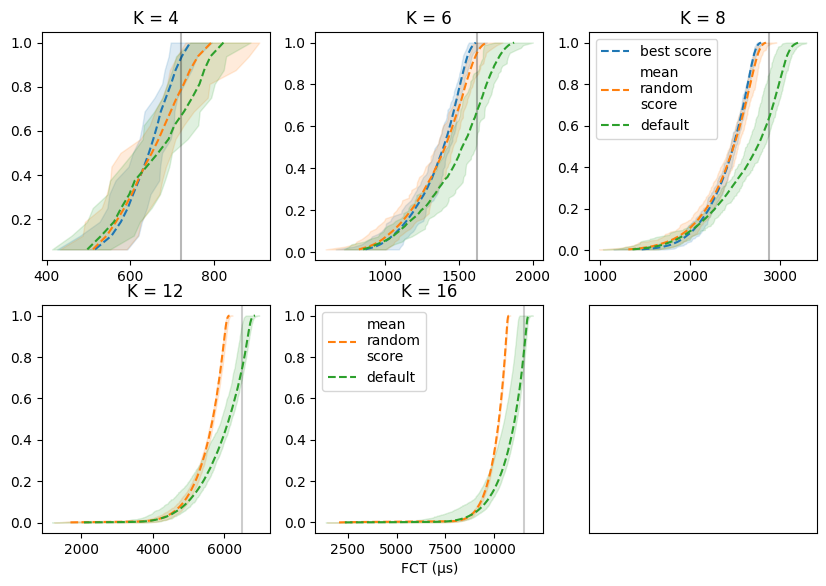

In [29]:
fig, ax = plt.subplots(2, 3, figsize = (10, 6.5))

ax[1, 1].set_xlabel("FCT (μs)")
for ind, (k, name) in enumerate(zip([4, 6, 8, 12, 16], [
    "full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group",
    "full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group",
    "full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group",
    "full_incast --K 12 --HT_FCT_KEEP all --INCAST_TYPE group",
    "full_incast --K 16 --HT_FCT_KEEP all --INCAST_TYPE group"
])):
    i, j = ind // ax.shape[1], ind % ax.shape[1]
    analyse_simple_plot_fcts(name, ax[i, j], show_legend = (i, j) in [(0, 2), (1, 1)])
    ax[i, j].set_title(f"K = {k}")

ax[1, 2].xaxis.set_visible(False)
ax[1, 2].yaxis.set_visible(False)

fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_area_full_incast_group_sender_kbig.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

0 rap fails = 0.264
len(ht[score]['fcts']) = 125
-6 rap fails = 0.136
len(ht[score]['fcts']) = 125
default rap fails = 0.0
len(ht[score]['fcts']) = 125
0 rap fails = 0.0
len(ht[score]['fcts']) = 250
-40 rap fails = 0.0
len(ht[score]['fcts']) = 250
default rap fails = 0.0
len(ht[score]['fcts']) = 250
-14 rap fails = 0.0
len(ht[score]['fcts']) = 425
-138 rap fails = 0.0
len(ht[score]['fcts']) = 425
default rap fails = 0.0
len(ht[score]['fcts']) = 425
0 rap fails = 0.0
len(ht[score]['fcts']) = 125
-6 rap fails = 0.0
len(ht[score]['fcts']) = 125
default rap fails = 0.0
len(ht[score]['fcts']) = 125
0 rap fails = 0.0
len(ht[score]['fcts']) = 250
-40 rap fails = 0.0
len(ht[score]['fcts']) = 250
default rap fails = 0.0
len(ht[score]['fcts']) = 250
-14 rap fails = 0.0
len(ht[score]['fcts']) = 425
-138 rap fails = 0.0
len(ht[score]['fcts']) = 425
default rap fails = 0.0
len(ht[score]['fcts']) = 425


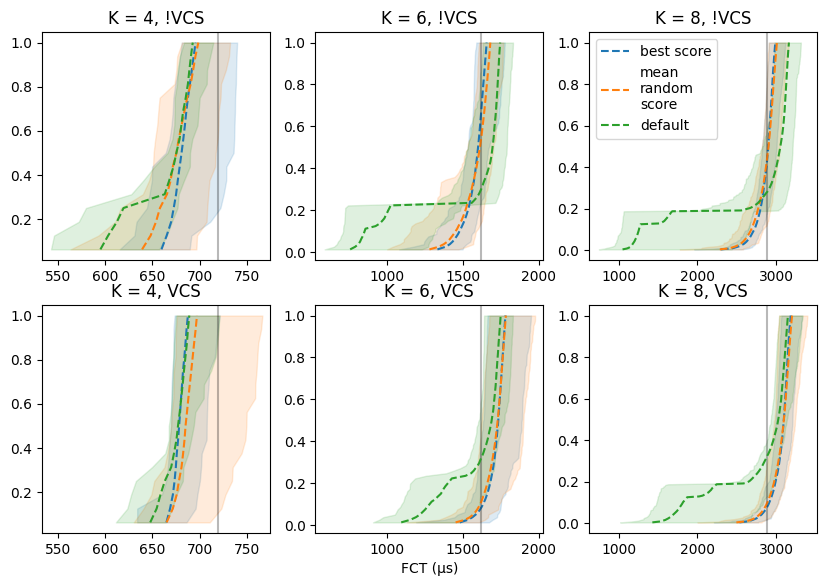

In [48]:
fig, ax = plt.subplots(2, 3, figsize = (10, 6.5))

ax[1, 1].set_xlabel("FCT (μs)")
for ind, (k, name) in enumerate(zip([4, 6, 8] * 2, [
    "full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc",
    "full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc",
    "full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc",
    "full_incast --HT_FCT_KEEP all --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS",
    "full_incast --HT_FCT_KEEP all --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS",
    "full_incast --HT_FCT_KEEP all --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc --VCS"
])):
    i, j = ind // ax.shape[1], ind % ax.shape[1]
    analyse_simple_plot_fcts(name, ax[i, j], show_legend = (i, j) == (0, 2))
    ax[i, j].set_title(f"K = {k}, {'!VCS' if i == 0 else 'VCS'}")

for j in range(ax.shape[1]):
    min_x = min([ax[i, j].get_xlim()[0] for i in range(2)])
    max_x = max([ax[i, j].get_xlim()[1] for i in range(2)])
    for i in range(2):
        ax[i, j].set_xlim([min_x, max_x])
    
fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_area_full_incast_group_pfc_no_vcs_vs_vcs.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

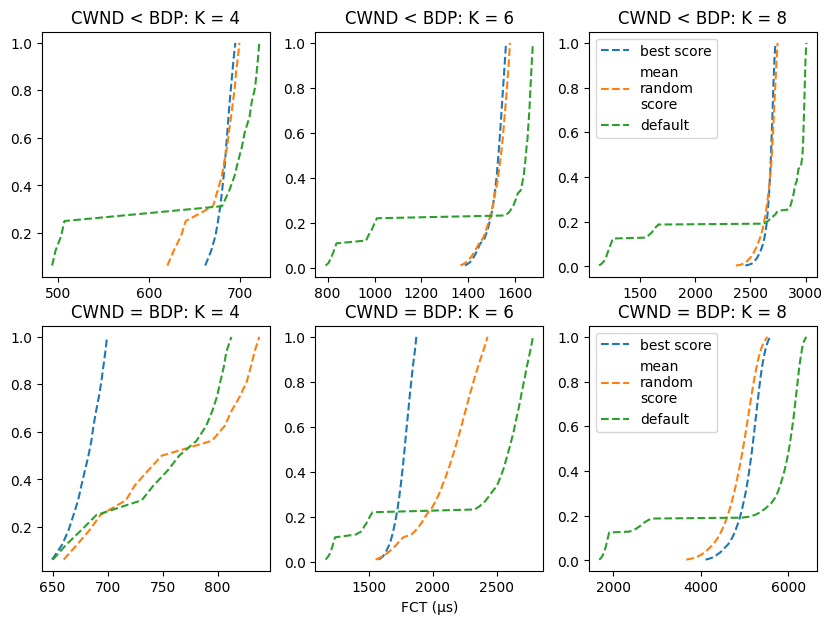

In [84]:
# DONTUSE

fig, ax = plt.subplots(2, 3, figsize = (10, 7))

for i, (k, name) in enumerate(zip([4, 6, 8], [
    "full_incast --K 4 --INCAST_TYPE group --DO_CC no_cc_pfc",
    "full_incast --K 6 --INCAST_TYPE group --DO_CC no_cc_pfc",
    "full_incast --K 8 --INCAST_TYPE group --DO_CC no_cc_pfc --CNT_RUNS_PER_TOPO 1"
])):
    analyse_simple_plot_fcts(name, ax[0, i], show_legend = i == 2)
    ax[0, i].set_title(f"CWND < BDP: K = {k}")
    
ax[1, 1].set_xlabel("FCT (μs)")
for i, k in enumerate([4, 6, 8]):
    analyse_simple_plot_fcts(f"old PFC full_incast group K = {k}", ax[1, i], show_legend = i == 2)
    ax[1, i].set_title(f"CWND = BDP: K = {k}")
    
fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_full_incast_group_pfc.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

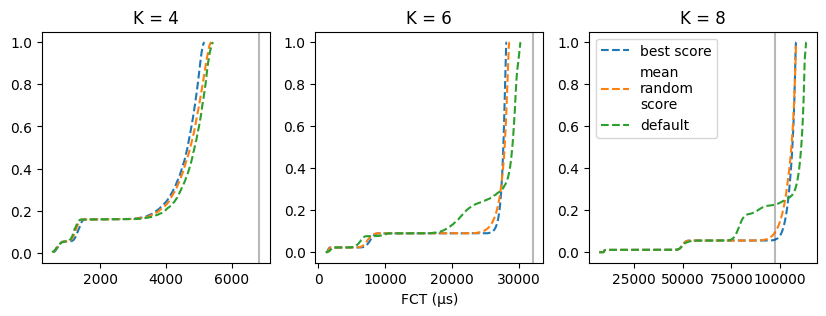

In [149]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))

ax[1].set_xlabel("FCT (μs)")
for i, (k, name) in enumerate(zip([4, 6, 8], [
    "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel",
    "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1",
    "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel --CNT_RUNS_PER_TOPO 1"
])):
    analyse_simple_plot_fcts(name, ax[i], show_legend = i == 2)
    ax[i].set_title(f"K = {k}")
  
fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_all_sender.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

score = '0', ht[score]['rap_failed_sims'] = 0.0
score = '-6', ht[score]['rap_failed_sims'] = 0.0
score = 'default', ht[score]['rap_failed_sims'] = 0.0
score = '0', ht[score]['rap_failed_sims'] = 0.08
score = '-40', ht[score]['rap_failed_sims'] = 0.12
score = 'default', ht[score]['rap_failed_sims'] = 0.2
score = '-14', ht[score]['rap_failed_sims'] = 0.6
score = '-138', ht[score]['rap_failed_sims'] = 0.96
score = 'default', ht[score]['rap_failed_sims'] = 1.0


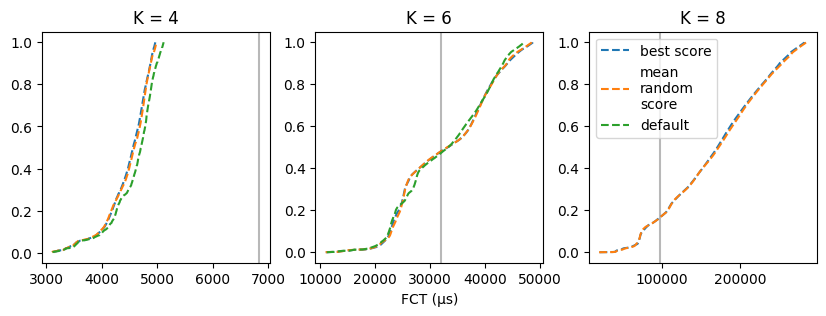

In [168]:
# TODO poate tragi si o dunga cu unde ar fi expected FCT.

# "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
# "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 2000000",
# "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited --CNT_RUNS_PER_TOPO 1 --END_TIME 20000000"

fig, ax = plt.subplots(1, 3, figsize = (10, 3))

ax[1].set_xlabel("FCT (μs)")
for i, (k, name) in enumerate(zip([4, 6, 8], [
    "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
    "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
    "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc"
])):
    analyse_simple_plot_fcts(name, ax[i], show_legend = i == 2)
    ax[i].set_title(f"K = {k}") # !CC, PFC: 

# fig.savefig(
#     f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_all_pfc_only.pdf",
#     bbox_inches = "tight", pad_inches = 1e-2
# )

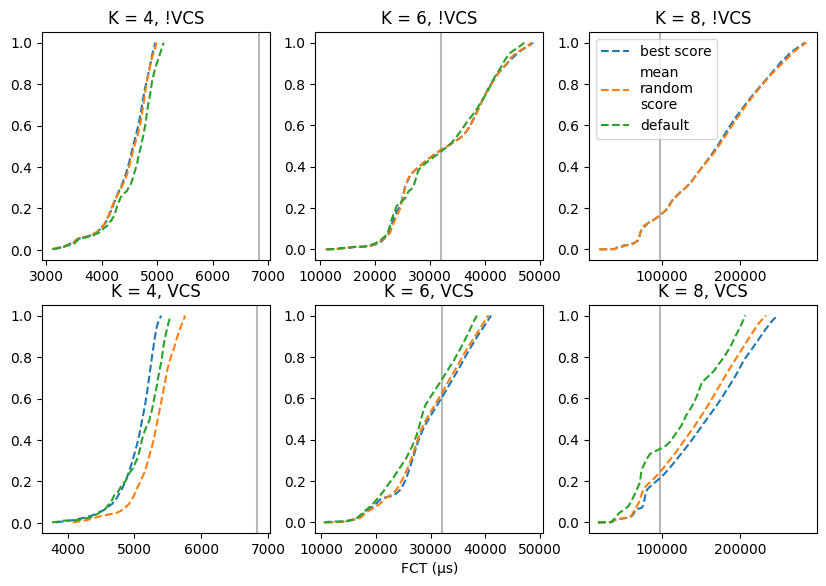

In [42]:
fig, ax = plt.subplots(2, 3, figsize = (10, 6.5))

ax[1, 1].set_xlabel("FCT (μs)")
for ind, (k, name) in enumerate(zip([4, 6, 8] * 2, [
    "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
    "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
    "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc",
    "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS",
    "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS",
    "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_pfc --VCS"
])):
    i, j = ind // ax.shape[1], ind % ax.shape[1]
    analyse_simple_plot_fcts(name, ax[i, j], show_legend = (i, j) == (0, 2))
    ax[i, j].set_title(f"K = {k}, {'!VCS' if i == 0 else 'VCS'}")

for j in range(ax.shape[1]):
    max_x = max([ax[i, j].get_xlim()[1] for i in range(2)])
    for i in range(2):
        ax[i, j].set_xlim([ax[i, j].get_xlim()[0], max_x])

fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_all_pfc_no_vcs_vs_vcs.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)

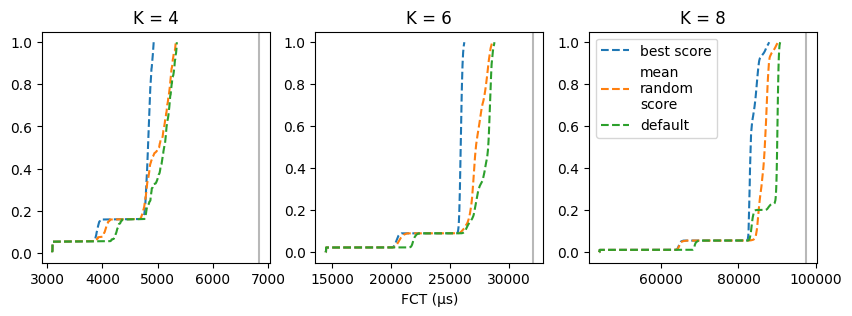

In [152]:
# TODO poate tragi si o dunga cu unde ar fi expected FCT.

fig, ax = plt.subplots(1, 3, figsize = (10, 3))

ax[1].set_xlabel("FCT (μs)")
for i, (k, name) in enumerate(zip([4, 6, 8], [
    "full_all_to_all --K 4 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited",
    "full_all_to_all --K 6 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited",
    "full_all_to_all --K 8 --ALL_TO_ALL_TYPE parallel_pfc --DO_CC no_cc_unlimited"
])):
    analyse_simple_plot_fcts(name, ax[i], show_legend = i == 2)
    ax[i].set_title(f"K = {k}") # !CC, inf QS, inf CWND:
    
fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/htsim_one_col_fig_all_to_all_inf_qs_cwnd.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)